# Diabetes Data Analysis - Demonstration Notebook
**Course:** Software Development for Data Science  |  **Topic:** Healthcare and Public Health Data Analysis

This notebook walks through the application's modules: **load -> inspect quality -> clean -> analyse -> visualise -> interpret**. It imports the same functions as `main.py`, so the notebook and the command-line tool cannot disagree.

**Dataset:** Pima Indians Diabetes Database, originally from the National Institute of Diabetes and Digestive and Kidney Diseases (Smith et al., 1988). It contains 768 women aged 21 or over of Pima Indian heritage, with 8 measurements and a diabetes outcome. The CSV was downloaded from the public GitHub repository `plotly/datasets`. See `DATA_ETHICS.md` for licensing and responsible use.

### Running in Google Colab
When this notebook is opened in Google Colab, the next cell clones the project from GitHub so that the `health_analytics` package can be imported. Edit `REPO_URL` to point to the repository. The cell does nothing when the notebook is run locally.

In [1]:
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.isdir("health_analytics"):
    REPO_URL = "https://github.com/YOUR-USERNAME/health-data-analyzer.git"
    subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("health-data-analyzer")
    print("Repository cloned; working directory:", os.getcwd())
else:
    print("Not running in Colab (or code already present); no setup needed.")

Not running in Colab (or code already present); no setup needed.


In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from health_analytics import analysis
from health_analytics.data_download import download_dataset
from health_analytics.data_loader import load_dataset
from health_analytics.preprocessing import preprocess_dataset, profile_data_quality
from health_analytics import visualization as viz

pd.set_option("display.max_columns", 20)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


## 1. Data input (Q2a)

In [3]:
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "diabetes.csv"
if not RAW_PATH.exists():
    download_dataset(RAW_PATH)

raw = load_dataset(RAW_PATH)
print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head(8)

Shape: 768 rows x 9 columns


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


## 2. Data-quality inspection (Q2b)
Before cleaning, we measure what is wrong with the raw data.

In [4]:
profile = profile_data_quality(raw)
print("Duplicate rows       :", profile["n_duplicate_rows"])
print("Cells marked missing :", sum(profile["missing_values"].values()))
print("\nData types:")
print(raw.dtypes.to_string())

Duplicate rows       : 0
Cells marked missing : 0

Data types:
pregnancies                     int64
glucose                         int64
blood_pressure                  int64
skin_thickness                  int64
insulin                         int64
bmi                           float64
diabetes_pedigree_function    float64
age                             int64
outcome                         int64


In [5]:
measures = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
zeros = pd.DataFrame({"zeros": (raw[measures] == 0).sum()})
zeros["percent"] = (zeros["zeros"] / len(raw) * 100).round(1)
print("A value of 0 is physiologically impossible for these measurements:")
zeros

A value of 0 is physiologically impossible for these measurements:


,zeros,percent
glucose,5,0.7
blood_pressure,35,4.6
skin_thickness,227,29.6
insulin,374,48.7
bmi,11,1.4


**Interpretation.** The file has no blank cells, no duplicates and every column is already numeric, so those problems do not occur in this dataset. The real quality problem is **hidden missing data**: zeros stored in place of unmeasured values. Insulin is missing for 374 patients (48.7%) and skin thickness for 227 (29.6%). A blood pressure, BMI or glucose of 0 cannot be real. Treating these zeros as real measurements would drag every mean downward and distort every chart.

## 3. Preprocessing (Q2b)
`preprocess_dataset` coerces types, nullifies impossible values (including the hidden zeros), removes duplicates, drops rows without an outcome, imputes the remaining gaps with the column median and derives features. The code handles blanks, text and duplicates too; those paths are exercised by the unit tests.

In [6]:
clean, report = preprocess_dataset(raw)
print(f"Rows: {report['profile_before']['n_rows']} -> {report['profile_after']['n_rows']}")
print(f"Missing cells after cleaning: {sum(report['profile_after']['missing_values'].values())}\n")
audit = pd.DataFrame({
    "nullified (impossible)": report["invalid_values_removed"],
    "imputed (median)": report["values_imputed"],
}).loc[lambda d: (d != 0).any(axis=1)]
audit

Rows: 768 -> 768
Missing cells after cleaning: 0



,nullified (impossible),imputed (median)
glucose,5,5
blood_pressure,36,36
skin_thickness,227,227
insulin,374,374
bmi,11,11


In [7]:
clean.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome,bmi_category,age_group,outcome_label
0,6,148,72,35,125,33.6,0.627,50,1,Obese,50-59,Diabetic
1,1,85,66,29,125,26.6,0.351,31,0,Overweight,30-39,Non-diabetic
2,8,183,64,29,125,23.3,0.672,32,1,Normal,30-39,Diabetic
3,1,89,66,23,94,28.1,0.167,21,0,Overweight,21-29,Non-diabetic
4,0,137,40,35,168,43.1,2.288,33,1,Obese,30-39,Diabetic


**Interpretation.** 653 impossible values were converted to missing and then filled with the column median. Median is used because it is robust to the skew in clinical measurements (insulin is strongly right-skewed). **Caution:** filling 49% of insulin with a single value is a strong assumption. It keeps all 768 patients but shrinks the variability of insulin and weakens its correlations. For this reason the summary statistics below are computed from the *observed* values only.

## 4. Statistical analysis (Q2c)

In [8]:
observed = report["observed_data"]
analysis.summary_statistics(observed)

,count,mean,median,std,min,q1,q3,max
pregnancies,768.0,3.85,3.00,3.37,0.00,1.00,6.00,17.00
glucose,763.0,121.69,117.00,30.54,44.00,99.00,141.00,199.00
blood_pressure,732.0,72.47,72.00,12.26,30.00,64.00,80.00,122.00
skin_thickness,541.0,29.15,29.00,10.48,7.00,22.00,36.00,99.00
insulin,394.0,155.55,125.00,118.78,14.00,76.25,190.00,846.00
bmi,757.0,32.46,32.30,6.92,18.20,27.50,36.60,67.10
diabetes_pedigree_function,768.0,0.47,0.37,0.33,0.08,0.24,0.63,2.42
age,768.0,33.24,29.00,11.76,21.00,24.00,41.00,81.00


**Interpretation.** The `count` column shows how many real measurements each variable has: 394 for insulin and 541 for skin thickness against 768 for age. Mean exceeds median for insulin (about 156 vs 125) and age (33.2 vs 29), so both are right-skewed. Most patients are young (median 29) but a tail reaches 81.

In [9]:
for col in ["outcome_label", "age_group", "bmi_category"]:
    print(analysis.frequency_distribution(clean, col).to_string(), "\n")

               count  percent
outcome_label                
Non-diabetic     500     65.1
Diabetic         268     34.9 

           count  percent
age_group                
21-29        396    51.56
30-39        165    21.48
40-49        118    15.36
50-59         57     7.42
60+           32     4.17 

              count  percent
bmi_category                
Obese           476    61.98
Overweight      180    23.44
Normal          108    14.06
Underweight       4     0.52 



In [10]:
print("Glucose (mg/dL) by outcome")
analysis.group_summary(clean, "outcome_label", "glucose")

Glucose (mg/dL) by outcome


,count,mean,median,std
outcome_label,,,,
Diabetic,268,142.13,140.0,29.57
Non-diabetic,500,110.68,107.5,24.71


In [11]:
print("Percentage of diabetic patients by age group")
analysis.outcome_rate_by_group(clean, "age_group")

Percentage of diabetic patients by age group


,patients,diabetic_percent
age_group,,
21-29,396,21.2
30-39,165,46.1
40-49,118,55.1
50-59,57,59.6
60+,32,28.1


In [12]:
print("Percentage of diabetic patients by BMI category")
analysis.outcome_rate_by_group(clean, "bmi_category")

Percentage of diabetic patients by BMI category


,patients,diabetic_percent
bmi_category,,
Normal,108,6.5
Obese,476,45.6
Overweight,180,24.4
Underweight,4,0.0


In [13]:
for finding in analysis.compute_key_findings(clean):
    print("-", finding)

- The dataset holds 768 patients with a mean age of 33.2 years; 268 (34.9%) have diabetes.
- Diabetic patients have a mean glucose of 142.1 mg/dL versus 110.7 for non-diabetic patients.
- Mean BMI is 35.4 for diabetic and 30.9 for non-diabetic patients.
- The diabetes rate is highest in age group '50-59' (59.6%) and lowest in '21-29' (21.2%).
- Glucose has the strongest correlation with diabetes status (r = 0.49); the weakest of all measurements is blood pressure (r = 0.16).
- 62.0% of patients fall in the Obese BMI band.


**Interpretation.**
- About 35% of patients (268 of 768) are diabetic, so the outcome classes are imbalanced (65 / 35).
- Mean glucose is 142.1 mg/dL for diabetic and 110.7 for non-diabetic patients, the largest difference of any measurement.
- The diabetes rate climbs with BMI: 6.5% in the Normal band, 24.4% Overweight, 45.6% Obese. Only 4 patients are Underweight, so that group (0%) is too small to interpret.
- The diabetes rate rises from 21.2% (ages 21-29) to 59.6% (50-59), then falls to 28.1% in the 60+ group, which has only 32 patients, so that drop may be sampling noise or a survivor effect and should not be over-read.

## 5. Visualisation (Q2d)
Six charts are generated and saved in `output/figures/`. Each outcome keeps the same colour in every chart.

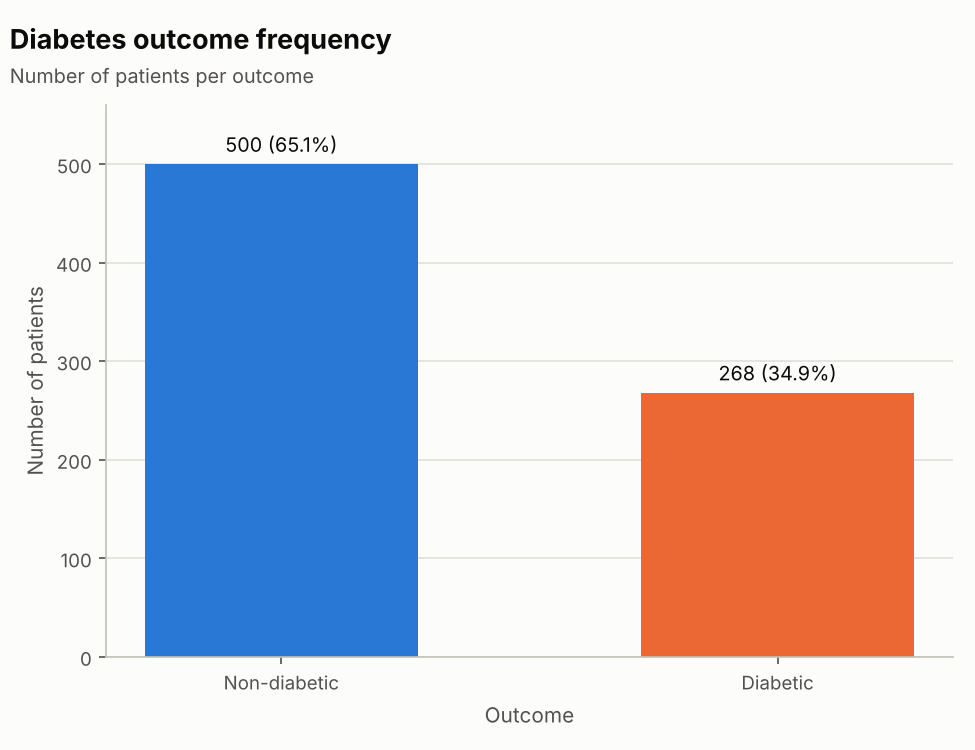

In [14]:
FIG_DIR = PROJECT_ROOT / "output" / "figures"
figures = viz.generate_all_figures(clean, FIG_DIR)
display(Image(filename=str(figures["outcome_frequency"])))

**Figure 1 - Outcome frequency.** 500 non-diabetic (65.1%) and 268 diabetic (34.9%) patients. Because of this imbalance, a model that always predicted *non-diabetic* would already be right 65% of the time, so accuracy alone would be a poor metric in any future modelling.

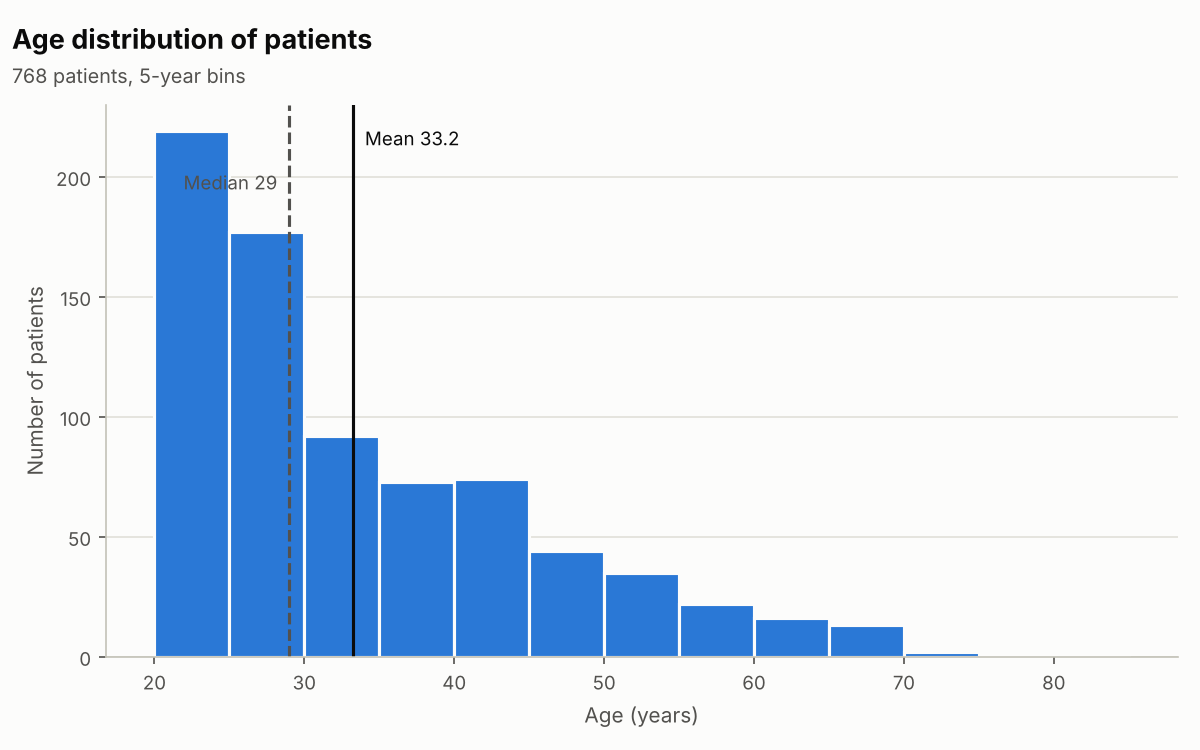

In [15]:
display(Image(filename=str(figures["age_distribution"])))

**Figure 2 - Age distribution.** Strongly right-skewed: the mean (33.2) sits above the median (29), and over half the patients are under 30. Findings therefore mainly describe younger women.

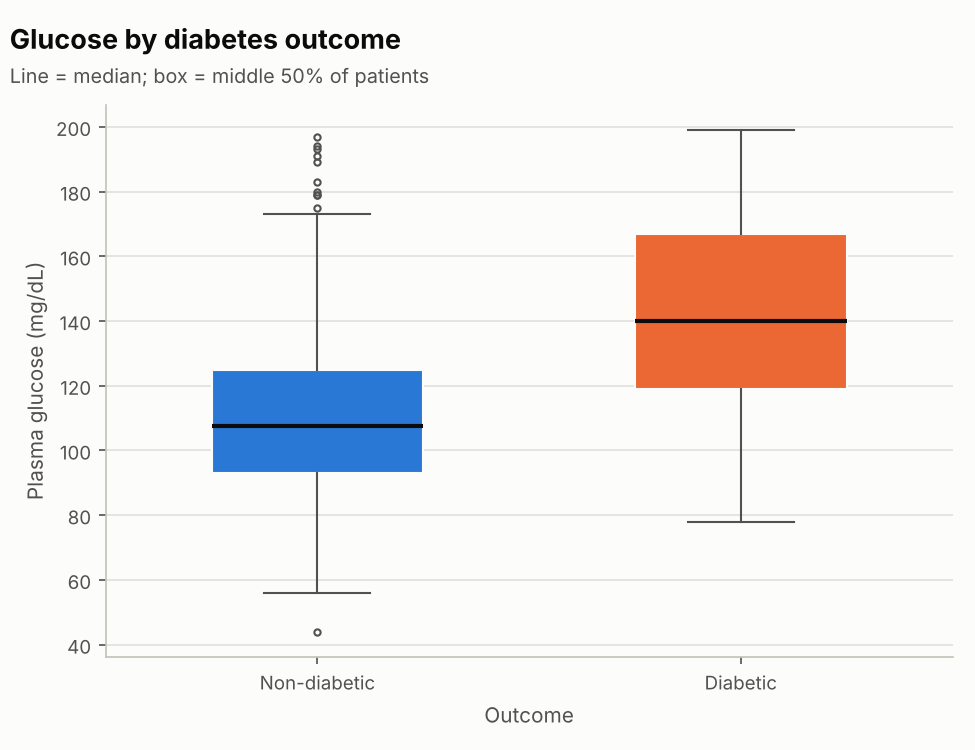

In [16]:
display(Image(filename=str(figures["glucose_by_outcome"])))

**Figure 3 - Glucose by outcome.** The diabetic median (140 mg/dL) is about 32 mg/dL above the non-diabetic median (107.5); the middle halves overlap only between 119 and 125 mg/dL. The boxes overlap only slightly in their middle halves, but whiskers overlap, so glucose is informative but not a perfect separator.

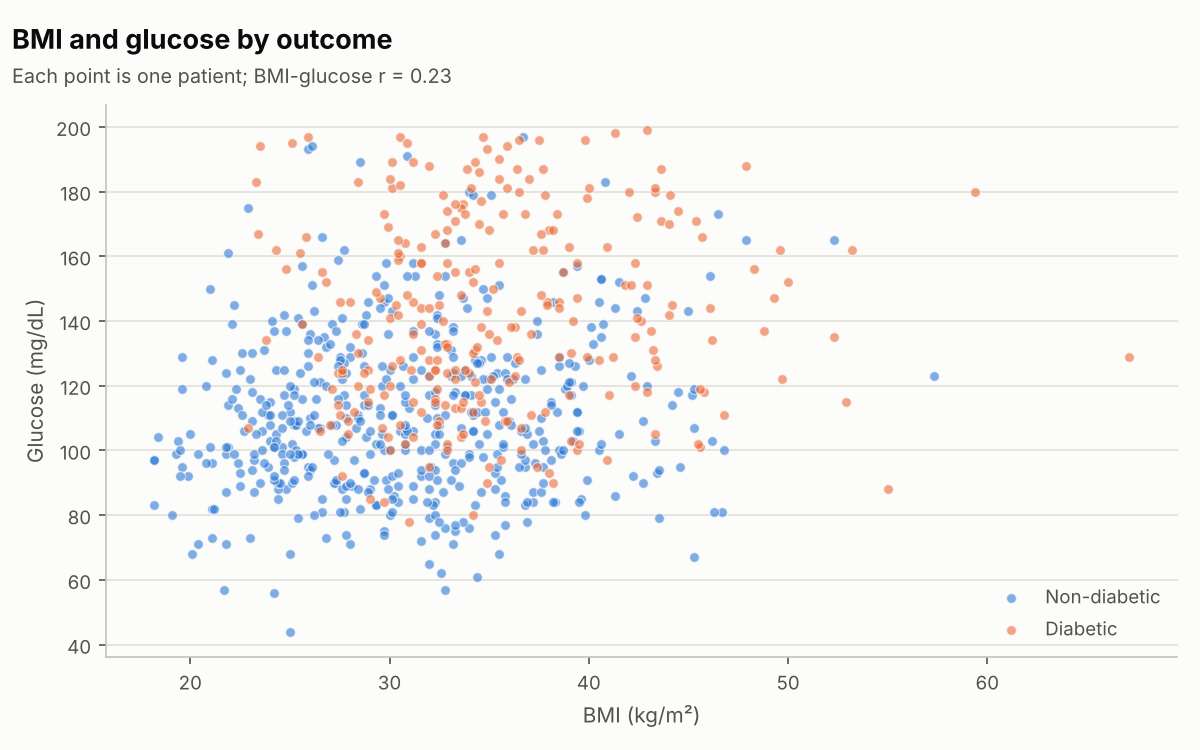

In [17]:
display(Image(filename=str(figures["bmi_vs_glucose"])))

**Figure 4 - BMI vs glucose.** A weak positive relationship (r = 0.23). Orange (diabetic) points concentrate at higher glucose and higher BMI, but there is wide scatter, so BMI alone predicts glucose poorly.

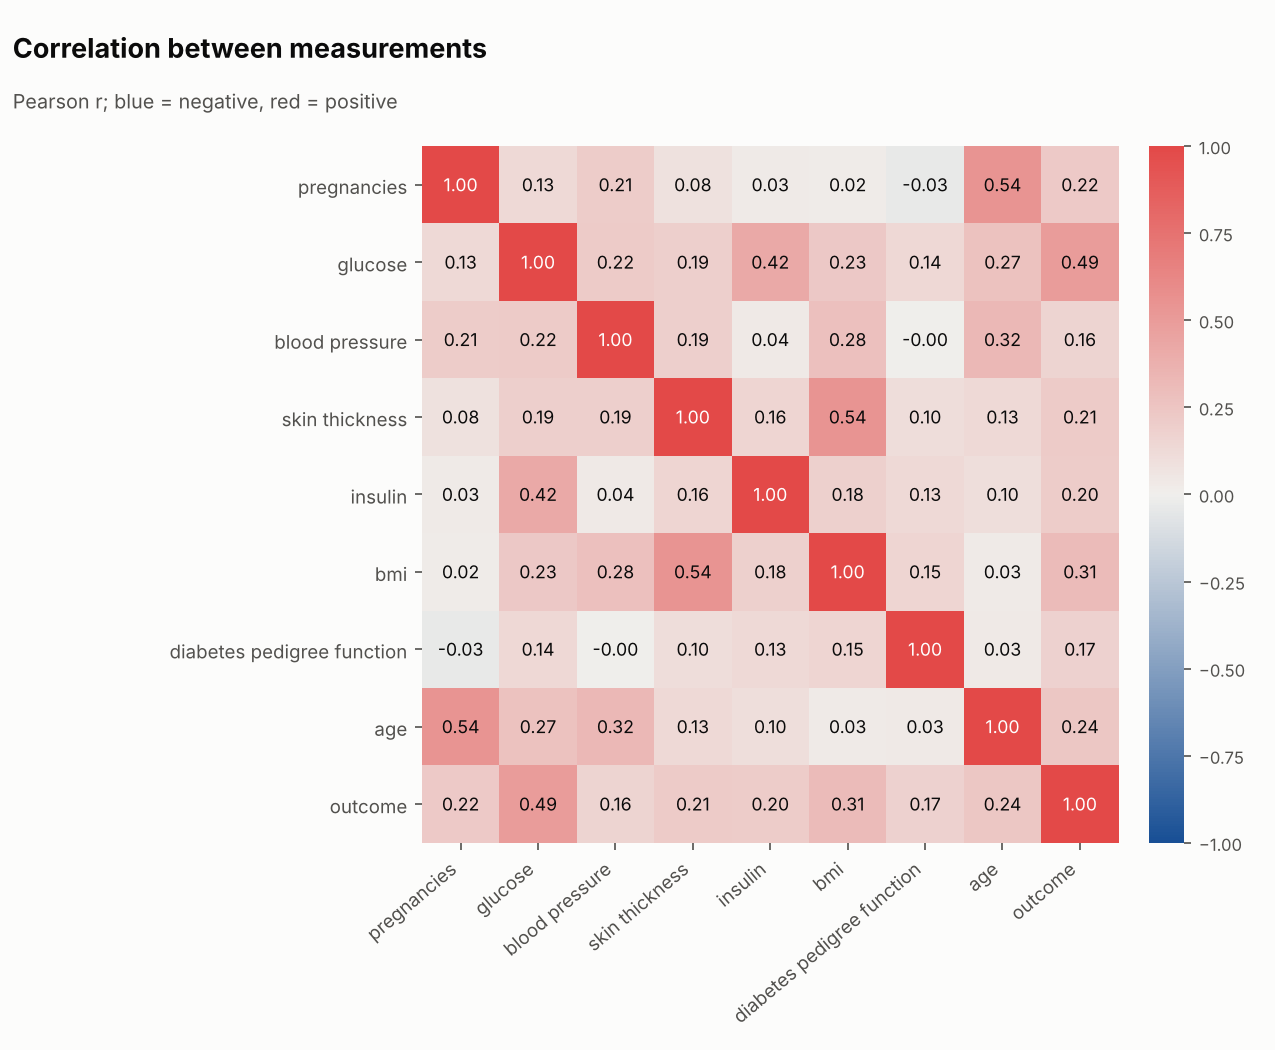

In [18]:
display(Image(filename=str(figures["correlation_heatmap"])))

**Figure 5 - Correlation heat map** (computed on the median-imputed data, so correlations involving insulin and skin thickness are weakened). Glucose has the strongest correlation with the outcome (r = 0.49), followed by BMI (0.31) and age (0.24). Age and pregnancies are correlated (0.54), as are BMI and skin thickness (0.54), both unsurprising. Correlation does not imply causation.

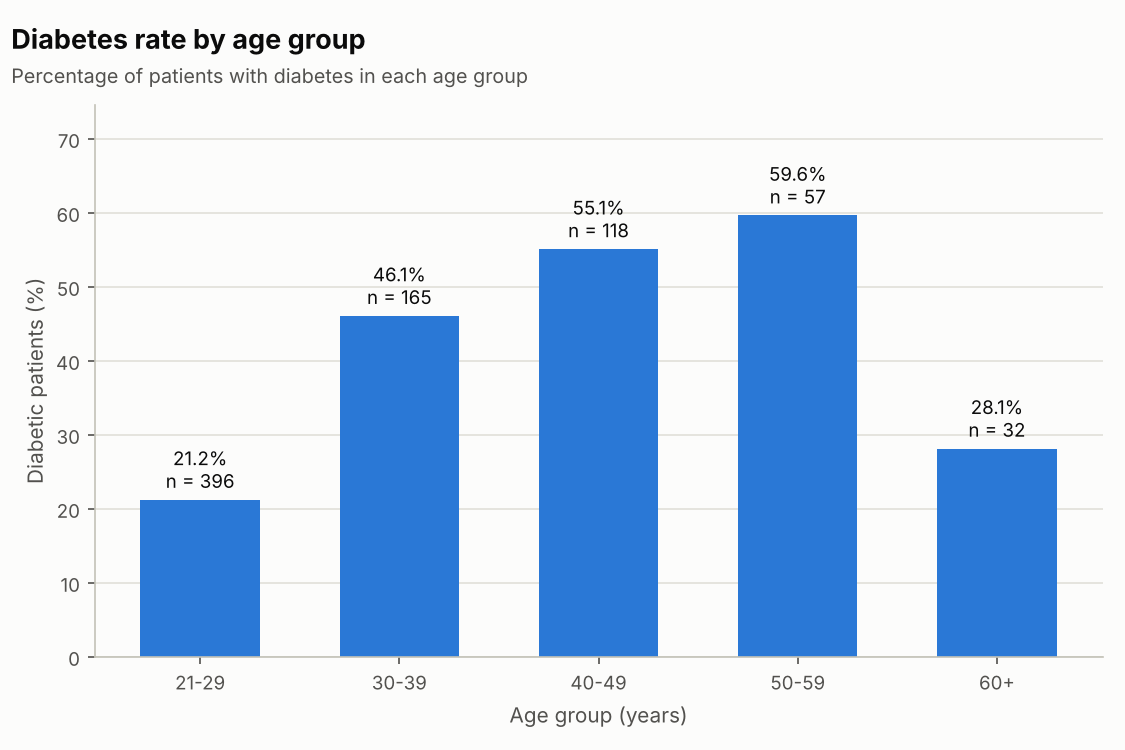

In [19]:
display(Image(filename=str(figures["diabetes_rate_by_age"])))

**Figure 6 - Diabetes rate by age group.** The rate rises through the 50s, then falls at 60+ where only 32 patients exist (n is printed on each bar). Always read percentages together with group size.

## 6. Conclusions and limitations
**Conclusions**
1. The pipeline turned a file with hidden missing values into an analysis-ready dataset, with every change counted.
2. Glucose, BMI and age are the measurements most associated with diabetes in this sample.
3. Diabetes is much more common among patients with obese BMI than among those with normal BMI.

**Limitations**
- The sample is 768 women of one population (Pima Indian heritage, aged 21+); results must not be generalised.
- Median imputation of insulin (48.7%) and skin thickness (29.6%) understates variability.
- Associations are descriptive; they do not show cause and effect.

**Future improvement:** compare imputation methods and train a cross-validated classifier that handles the class imbalance.